# Phase 3: Measurement-driven search starting from the imatrix presets

**What Phase 2b taught us.** Single-tensor probes are too noisy to build a damage model: the fitted damage at q4_k/q5_k/q6_k collapsed to zero, the optimizer's predicted damage was about 0 everywhere, and the real damage of its configurations was 6-10%. The one strong signal was `token_embd` (+16% perplexity at q3_k) and a few edge tensors.

**Design of this phase.** No damage model. The search uses **real whole-model measurements only**:
- **Seed = a real preset** (imatrix Q4_K_M by default). The per-tensor types of the preset are read from the file, so the search starts exactly where the strongest baseline is.
- **Variables = tensor families** (kind x position: first 2 blocks / middle / last 2 blocks, plus the embedding), about 22 variables instead of 197.
- **Moves** shift a whole family one precision level, usually as a pair (one family up, another down) so the file never exceeds the preset's size. Exact size model, no guessing.
- **Accept only if the measured perplexity improves** on a *search* text slice (train split). So the result can never be worse than the seed **on the search text**. The final numbers use the *test* split, which the search never sees, so improvements that came from overfitting to the search text will show up as a gap.
- **Control:** the same search with random move proposals and the same evaluation budget. If guided does not beat random, the prior is not helping.
- **Second metric:** HellaSwag accuracy (400 tasks) through `llama-perplexity`, and GPU speed through `llama-bench`.

**Before the search** two short experiments test the Phase 2b explanation: (A) how much does the embedding at q4/q5/q6 cost? (B) are damages of different families additive?

**No guarantee of a win.** The presets are well tuned, so the honest outcomes are: a small real gain, a tie (then the case rests on speed and the analysis), or no gain. Every outcome is reported with the same numbers.

**Before running:** Accelerator = GPU T4 x2 or P100, Internet = On (Settings should offer "Turn off internet"). Run cells in order from the top. **Use an interactive session**, and **download `results/phase3_*.jsonl` after each long stage**, because a session reset deletes everything (it did last time).

**Time (rough estimate, not measured):** setup 25 min; preset anatomy about 10 min per seed; experiments about 10 min; each search evaluation is probably 70-110 s because quantizing with an imatrix is slow on 4 cores. At 45 evaluations per run and two runs (guided and random) that is about 1.5-2.5 h per seed. The notebook prints real timings after the first evaluation.

In [5]:
import os, json, re, time, subprocess, pathlib, shutil, random, math
import numpy as np

os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # measure on ONE GPU even if Kaggle gives T4 x2

MODEL_ID    = "Qwen/Qwen2.5-1.5B"
MODEL_NAME  = MODEL_ID.split("/")[-1]

LEVELS      = ["q3_k", "q4_k", "q5_k", "q6_k", "q8_0"]   # allowed per-tensor types, low -> high bits
HIGH        = LEVELS[-1]
SEEDS       = ["Q4_K_M"]     # presets to improve on; add "Q3_K_M" for a second size budget
N_EVALS     = 45             # search evaluations per run (guided and random each get this many)
SEARCH_CHUNKS = 80           # 512-token chunks of the SEARCH text per candidate
PPL_CHUNKS  = 100            # chunks of the TEST split for final numbers
IMX_CHUNKS  = 200
ACCEPT_REL  = 0.0003         # a move must lower search perplexity by at least 0.03% to be accepted
EXPLORE     = 0.2            # guided policy: probability of a random move instead of the best-prior move
N_EDGE      = 2              # first/last N blocks form the "edge" families
BENCH       = True           # GPU tokens/s with llama-bench for presets and final candidates
RUN_HELLASWAG = True         # second quality metric (skipped automatically if it cannot run)
HS_TASKS    = 400
SAVE_FINAL_GGUFS = True      # write preset + final configs as .gguf into results/final_models for the laptop
CLEANUP     = True

WORK    = pathlib.Path("/kaggle/working")
LLAMA   = WORK / "llama.cpp"
BIN     = LLAMA / "build" / "bin"
MODELS  = WORK / "models"
RESULTS = WORK / "results"
for d in (MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if check and r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
        raise RuntimeError("command failed: " + cmd)
    return (r.stdout + r.stderr).strip()

print(sh("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv"))
for host in ["github.com", "huggingface.co", "pypi.org"]:
    r = subprocess.run(["curl", "-sS", "-o", "/dev/null", "-m", "10", "-w", "%{http_code}", f"https://{host}"],
                       capture_output=True, text=True)
    print(host, "->", r.stdout or r.stderr.strip())

$ nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv
name, memory.total [MiB], compute_cap
Tesla T4, 15360 MiB, 7.5
Tesla T4, 15360 MiB, 7.5
github.com -> 200
huggingface.co -> 200
pypi.org -> 200


## 1. Build llama.cpp (quantize, perplexity, imatrix, bench)
Needs internet: the three lines above must show `200`, `301` or `302`.

In [6]:
arch = 75   # T4; use 60 if you got a P100

if not (BIN / "llama-quantize").exists():
    if not LLAMA.exists():
        sh(f"git clone --depth 1 https://github.com/ggml-org/llama.cpp {LLAMA}")
    shutil.rmtree(LLAMA / "build", ignore_errors=True)
    if not shutil.which("nvcc") and os.path.exists("/usr/local/cuda/bin/nvcc"):
        os.environ["PATH"] += ":/usr/local/cuda/bin"
    cfg = (f"cmake -S {LLAMA} -B {LLAMA/'build'} -DGGML_CUDA=ON "
           f"-DCMAKE_CUDA_ARCHITECTURES={arch} -DGGML_CUDA_NO_VMM=ON "
           f"-DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release")
    r = subprocess.run(cfg, shell=True, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[:4000])
        raise RuntimeError("cmake configure failed")
    sh(f"cmake --build {LLAMA/'build'} --config Release -j {os.cpu_count()} "
       f"--target llama-quantize llama-perplexity llama-imatrix llama-bench")

LLAMA_COMMIT = sh(f"git -C {LLAMA} rev-parse --short HEAD", check=False)
print("llama.cpp commit:", LLAMA_COMMIT)
print("per-tensor override flag available:", "--tensor-type" in sh(f"{BIN/'llama-quantize'} --help", check=False))

$ git -C /kaggle/working/llama.cpp rev-parse --short HEAD
llama.cpp commit: 6b9ba4f
$ /kaggle/working/llama.cpp/build/bin/llama-quantize --help
per-tensor override flag available: True


## 2. Model, F16 GGUF and text slices
`--no-deps` keeps pip from touching numpy (last time a mid-session numpy change broke SciPy).
- **imatrix text:** first 3M characters of the WikiText-2 *train* split
- **search text:** a different 300k-character slice of *train* (used for accept/reject decisions)
- **test text:** the *test* split (only for reported numbers)

In [7]:
sh(f"pip install -q --no-deps {LLAMA/'gguf-py'} sentencepiece")

from huggingface_hub import snapshot_download
hf_dir = snapshot_download(
    MODEL_ID, local_dir=str(WORK / "hf" / MODEL_NAME),
    allow_patterns=["*.json", "*.safetensors", "*.model", "*.txt", "tokenizer*"])
N_BLOCKS = json.load(open(pathlib.Path(hf_dir) / "config.json"))["num_hidden_layers"]
print("transformer blocks:", N_BLOCKS)

F16 = MODELS / f"{MODEL_NAME}-F16.gguf"
if not F16.exists():
    sh(f"python {LLAMA/'convert_hf_to_gguf.py'} {hf_dir} --outfile {F16} --outtype f16")
print(F16.name, f"{F16.stat().st_size/1e6:.0f} MB")

def get_text(split):
    try:
        from datasets import load_dataset
        return "".join(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split=split)["text"])
    except Exception as e:
        print("datasets route failed, using parquet:", repr(e)[:150])
        import pandas as pd
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("Salesforce/wikitext", f"wikitext-2-raw-v1/{split}-00000-of-00001.parquet",
                            repo_type="dataset")
        return "".join(pd.read_parquet(p)["text"])

WIKI, IMX_TEXT, SEARCH_TEXT = WORK / "wiki.test.raw", WORK / "imx.train.txt", WORK / "search.train.txt"
if not WIKI.exists():
    WIKI.write_text(get_text("test"))
if not IMX_TEXT.exists() or not SEARCH_TEXT.exists():
    train = get_text("train")
    assert len(train) > 5_400_000, "train split shorter than expected"
    IMX_TEXT.write_text(train[:3_000_000])
    SEARCH_TEXT.write_text(train[5_000_000:5_300_000])
print({p.name: f"{p.stat().st_size/1e6:.2f} MB" for p in (WIKI, IMX_TEXT, SEARCH_TEXT)})

$ pip install -q --no-deps /kaggle/working/llama.cpp/gguf-py sentencepiece


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

transformer blocks: 28
Qwen2.5-1.5B-F16.gguf 3094 MB
{'wiki.test.raw': '1.29 MB', 'imx.train.txt': '3.01 MB', 'search.train.txt': '0.30 MB'}


## 3. Importance matrix (saved to `results/` for reuse)

In [8]:
IMATRIX = MODELS / f"{MODEL_NAME}.imatrix"
IMATRIX_SAVED = RESULTS / f"{MODEL_NAME}.imatrix"
if IMATRIX_SAVED.exists() and not IMATRIX.exists():
    shutil.copy(IMATRIX_SAVED, IMATRIX)
if not IMATRIX.exists():
    t = time.time()
    sh(f"{BIN/'llama-imatrix'} -m {F16} -f {IMX_TEXT} -o {IMATRIX} -ngl 99 -c 512 --chunks {IMX_CHUNKS}")
    shutil.copy(IMATRIX, IMATRIX_SAVED)
    print(f"imatrix done in {time.time()-t:.0f}s")
print("imatrix:", IMATRIX.name, f"{IMATRIX.stat().st_size/1e6:.1f} MB")

imatrix: Qwen2.5-1.5B.imatrix 4.1 MB


## 4. Helpers: quantize, measure, log (resumable)
A configuration is an array with one level index per weight tensor (`LEVELS[i]`). `measure` quantizes it with the imatrix, evaluates perplexity, optionally benchmarks, and deletes the temporary file. `log` appends the result to a JSONL file so a restarted session can pick up where it stopped.

In [9]:
BPW = {"q3_k": 3.4375, "q4_k": 4.5, "q5_k": 5.5, "q6_k": 6.5625, "q8_0": 8.5}
BPW_ALL = {**BPW, "q2_k": 2.625, "q4_0": 4.5, "q5_0": 5.5, "q4_1": 5.0, "q5_1": 6.0, "f16": 16.0, "bf16": 16.0, "f32": 32.0}

def exact_regex(names):
    return "^(" + "|".join(re.escape(n) for n in names) + ")$"

def run(cmd):
    r = subprocess.run(cmd, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-3000:])
        raise RuntimeError("failed: " + " ".join(map(str, cmd))[:300])
    return r.stdout, r.stderr

QUANT, PPLBIN, BENCHBIN = (str(BIN / n) for n in ("llama-quantize", "llama-perplexity", "llama-bench"))

def quantize(out, base, overrides=(), imatrix=True):
    cmd = [QUANT, "--imatrix", str(IMATRIX)] if imatrix else [QUANT]
    for pattern, qtype in overrides:
        cmd += ["--tensor-type", f"{pattern}={qtype}"]
    cmd += [str(F16), str(out), base]
    run(cmd)

def perplexity(path, text, chunks):
    cmd = [PPLBIN, "-m", str(path), "-f", str(text), "-ngl", "99", "-c", "512"]
    if chunks:
        cmd += ["--chunks", str(chunks)]
    so, se = run(cmd)
    m = re.search(r"Final estimate: PPL = ([\d.]+) \+/- ([\d.]+)", so + se)
    if not m:
        raise RuntimeError((so + se)[-2000:])
    return float(m.group(1)), float(m.group(2))

def bench(path):
    so, se = run([BENCHBIN, "-m", str(path), "-p", "512", "-n", "128", "-r", "3", "-ngl", "99", "-o", "json"])
    rows = json.loads(so[so.index("["):])
    pp = next(r for r in rows if r["n_prompt"] > 0 and r["n_gen"] == 0)
    tg = next(r for r in rows if r["n_gen"] > 0 and r["n_prompt"] == 0)
    return pp["avg_ts"], tg["avg_ts"]

HS_FILE = WORK / "hellaswag_val_full.txt"
HS_OK = [RUN_HELLASWAG]
def hellaswag(path):
    if not HS_OK[0]:
        return None
    try:
        if not HS_FILE.exists():
            import urllib.request
            urllib.request.urlretrieve("https://raw.githubusercontent.com/klosax/hellaswag_text_data/main/hellaswag_val_full.txt", HS_FILE)
        so, se = run([PPLBIN, "-m", str(path), "-f", str(HS_FILE), "--hellaswag",
                      "--hellaswag-tasks", str(HS_TASKS), "-ngl", "99"])
        rows = re.findall(r"^\s*(\d+)\s+([\d.]+)%", so + se, re.M)
        return float(rows[-1][1]) if rows else None
    except Exception as e:
        print("hellaswag skipped:", repr(e)[:200])
        HS_OK[0] = False
        return None

def tensor_types(path):
    from gguf import GGUFReader
    return {t.name: t.tensor_type.name for t in GGUFReader(str(path)).tensors}

# groups = every 2-D weight matrix of the model (norms and biases are 1-D and stay F32)
from gguf import GGUFReader
GROUPS = [{"id": t.name, "n": int(t.n_elements)} for t in GGUFReader(str(F16)).tensors if len(t.shape) == 2]
_pat = re.compile(r"blk\.(\d+)\.(\w+)\.weight")
for g in GROUPS:
    m = _pat.fullmatch(g["id"])
    g["block"] = int(m.group(1)) if m else -1
    g["kind"] = m.group(2) if m else g["id"].replace(".weight", "")
N_ELEM = np.array([g["n"] for g in GROUPS], dtype=float)
G = len(GROUPS)
print(f"{G} weight tensors, {N_ELEM.sum()/1e6:.0f}M weights")

FIXED_BYTES = None            # set by the self-test
BPW_VEC = np.array([BPW[l] for l in LEVELS])
def size_mb(idx):
    return (FIXED_BYTES + (N_ELEM * BPW_VEC[idx] / 8.0).sum()) / 1e6

def overrides_from_idx(idx):
    by_level = {}
    for g, l in zip(GROUPS, idx):
        if LEVELS[l] != HIGH:
            by_level.setdefault(LEVELS[l], []).append(g["id"])
    return [(exact_regex(names), lvl) for lvl, names in by_level.items()]

RESULTS_FILE = RESULTS / f"phase3_{MODEL_NAME}.jsonl"
records = {}
if RESULTS_FILE.exists():
    for line in RESULTS_FILE.read_text().splitlines():
        r = json.loads(line)
        records[r["name"]] = r

def log(name, rec, **meta):
    rec = {"name": name, **rec, **meta}
    records[name] = rec
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(rec) + "\n")
    return rec

def measure(idx, text, chunks, do_bench=False, do_hs=False, tag="tmp"):
    out = MODELS / f"tmp_{tag}.gguf"
    t = time.time()
    quantize(out, HIGH, overrides_from_idx(idx))
    ppl, err = perplexity(out, text, chunks)
    rec = {"size_mb": out.stat().st_size / 1e6, "ppl": ppl, "ppl_err": err}
    if do_bench and BENCH:
        rec["pp_tps"], rec["tg_tps"] = bench(out)
    if do_hs:
        rec["hellaswag"] = hellaswag(out)
    out.unlink()
    rec["secs"] = time.time() - t
    return rec

def evaluate_cfg(name, idx, text, chunks, do_bench=False, do_hs=False, **meta):
    if name in records:
        return records[name]
    rec = measure(idx, text, chunks, do_bench, do_hs, tag=name)
    return log(name, rec, levels=[LEVELS[int(i)] for i in idx], **meta)

def idx_of(rec):
    return np.array([LEVELS.index(l) for l in rec["levels"]])

197 weight tensors, 1544M weights


## 5. Self-test (run before anything long)
Per-tensor overrides must apply, and the size model must match real file sizes. The numbers feed the search's feasibility check, so a failure here must be fixed first.

In [10]:
plain = MODELS / "selftest_plain.gguf"; mixed = MODELS / "selftest_mixed.gguf"
quantize(plain, HIGH, [], imatrix=False)
FIXED_BYTES = plain.stat().st_size - (N_ELEM * BPW[HIGH] / 8.0).sum()      # norms, biases, metadata
print(f"fixed (non-group) bytes: {FIXED_BYTES/1e6:.1f} MB")

a, b = GROUPS[0], GROUPS[-1] if GROUPS[-1]["id"] != GROUPS[0]["id"] else GROUPS[1]
quantize(mixed, HIGH, [(exact_regex([a["id"]]), "q3_k"), (exact_regex([b["id"]]), "q5_k")], imatrix=False)
tt = tensor_types(mixed)
print(a["id"], "->", tt[a["id"]], "|", b["id"], "->", tt[b["id"]])
others = {v for k, v in tt.items() if k not in (a["id"], b["id"]) and "norm" not in k and not k.endswith(".bias")}
print("all other weight tensors:", others)
idx_t = np.full(G, len(LEVELS) - 1)
idx_t[0 if a is GROUPS[0] else 1] = LEVELS.index("q3_k")
idx_t[G - 1 if b is GROUPS[-1] else 1] = LEVELS.index("q5_k")
pred, act = size_mb(idx_t), mixed.stat().st_size / 1e6
print(f"size model: predicted {pred:.1f} MB, actual {act:.1f} MB, error {100*(pred/act-1):+.2f}%")
plain.unlink(); mixed.unlink()
assert tt[a["id"]] == "Q3_K" and tt[b["id"]] == "Q5_K" and others == {"Q8_0"}, "overrides not applied as expected: paste this output"
assert abs(pred / act - 1) < 0.02, "size model off by more than 2%: paste this output"
print("OK: overrides and size model work")

fixed (non-group) bytes: 6.5 MB
token_embd.weight -> Q3_K | blk.9.attn_v.weight -> Q5_K
all other weight tensors: {'Q8_0'}
size model: predicted 1498.7 MB, actual 1498.7 MB, error +0.00%
OK: overrides and size model work


## 6. Anatomy of the presets
For each seed preset (with imatrix): the per-tensor types are read from the file, the preset is evaluated on the search text and the test text, and the types are mapped onto our levels. This shows **what a well-tuned preset actually does** (for example how many bits the embedding gets) and gives the search its starting point.

In [11]:
def nearest_level(tname):
    b = BPW_ALL.get(tname.lower(), 8.5)
    return min(range(len(LEVELS)), key=lambda i: abs(BPW[LEVELS[i]] - b))

def preset_record(q):
    name = f"preset_imx_{q}"
    if name in records:
        return records[name]
    out = MODELS / f"tmp_{name}.gguf"
    t = time.time()
    quantize(out, q, [], imatrix=True)
    tt = tensor_types(out)
    idx = [nearest_level(tt[g["id"]]) for g in GROUPS]
    unmapped = sum(1 for g in GROUPS if tt[g["id"]].lower() not in BPW)
    rec = {"size_mb": out.stat().st_size / 1e6}
    rec["ppl"], rec["ppl_err"] = perplexity(out, WIKI, PPL_CHUNKS)
    rec["ppl_search"], _ = perplexity(out, SEARCH_TEXT, SEARCH_CHUNKS)
    if BENCH:
        rec["pp_tps"], rec["tg_tps"] = bench(out)
    rec["hellaswag"] = hellaswag(out)
    out.unlink()
    rec["secs"] = time.time() - t
    print(f"{name}: size={rec['size_mb']:.0f} MB test ppl={rec['ppl']:.4f} search ppl={rec['ppl_search']:.4f} "
          f"unmapped tensors={unmapped}")
    return log(name, rec, levels=[LEVELS[i] for i in idx], types=[tt[g["id"]] for g in GROUPS], unmapped=unmapped)

for q in SEEDS:
    preset_record(q)
evaluate_cfg("ref_q8_test", np.full(G, len(LEVELS) - 1), WIKI, PPL_CHUNKS, group="ref")
evaluate_cfg("ref_q8_search", np.full(G, len(LEVELS) - 1), SEARCH_TEXT, SEARCH_CHUNKS, group="ref")

import pandas as pd
for q in SEEDS:
    r = records[f"preset_imx_{q}"]
    d = pd.DataFrame({"kind": [g["kind"] for g in GROUPS], "block": [g["block"] for g in GROUPS],
                      "bpw": [BPW_ALL.get(t.lower(), np.nan) for t in r["types"]]})
    d["part"] = np.where(d.block < 0, "n/a", np.where(d.block < N_EDGE, "first blocks",
                         np.where(d.block >= N_BLOCKS - N_EDGE, "last blocks", "middle")))
    print(f"\nMean bits per weight of the imatrix {q} preset, by kind and position:")
    display(d.pivot_table(index="kind", columns="part", values="bpw", aggfunc="mean").round(2))
    print("embedding type:", r["types"][[g['kind'] for g in GROUPS].index('token_embd')] if any(g['kind']=='token_embd' for g in GROUPS) else "n/a")

preset_imx_Q4_K_M: size=986 MB test ppl=9.9820 search ppl=8.9310 unmapped tensors=0

Mean bits per weight of the imatrix Q4_K_M preset, by kind and position:


part,first blocks,last blocks,middle,n/a
kind,,,,
attn_k,4.50,4.50,4.50,NaN
attn_output,4.50,4.50,4.50,NaN
attn_q,4.50,4.50,4.50,NaN
attn_v,6.56,6.56,5.36,NaN
ffn_down,6.56,6.56,5.36,NaN
ffn_gate,4.50,4.50,4.50,NaN
ffn_up,4.50,4.50,4.50,NaN
token_embd,NaN,NaN,NaN,6.56


embedding type: Q6_K


## 7. Two quick experiments that test the Phase 2b explanation
**A. The embedding.** All tensors at q8_0 except `token_embd` at q4/q5/q6. If it costs several percent at q4_k, the optimizer's leftover q4_k embedding explains most of its failure.
**B. Additivity.** Three families at q3_k alone, then together. If the joint damage is much larger than the sum of the parts, damages interact and a sum-of-parts model cannot work.

In [12]:
HI = len(LEVELS) - 1
ref_s = evaluate_cfg("expA_ref", np.full(G, HI), SEARCH_TEXT, SEARCH_CHUNKS, group="exp")["ppl"]

emb = [i for i, g in enumerate(GROUPS) if g["kind"] == "token_embd"]
print("EXPERIMENT A: embedding precision (everything else q8_0), perplexity increase on the search text")
for lvl in ["q4_k", "q5_k", "q6_k"]:
    cfg = np.full(G, HI); cfg[emb] = LEVELS.index(lvl)
    p = evaluate_cfg(f"expA_embd_{lvl}", cfg, SEARCH_TEXT, SEARCH_CHUNKS, group="exp")["ppl"]
    print(f"  token_embd at {lvl}: ppl {p:.4f}  ({100*(p/ref_s-1):+.2f}%)")

def kind_idx(kind):
    return [i for i, g in enumerate(GROUPS) if g["kind"] == kind]

def damage(name, kinds, lvl="q3_k"):
    cfg = np.full(G, HI)
    for k in kinds:
        cfg[kind_idx(k)] = LEVELS.index(lvl)
    p = evaluate_cfg(name, cfg, SEARCH_TEXT, SEARCH_CHUNKS, group="exp")["ppl"]
    return math.log(p / ref_s)

print("\nEXPERIMENT B: additivity (all blocks of the kind at q3_k, everything else q8_0), damage in nats")
K = ["ffn_down", "attn_v", "ffn_up"]
d = {k: damage(f"expB_{k}", [k]) for k in K}
d_ab = damage("expB_down_v", K[:2]); d_abc = damage("expB_all3", K)
print("  single:", {k: round(v, 4) for k, v in d.items()})
print(f"  {K[0]}+{K[1]}: joint {d_ab:.4f} vs sum of singles {d[K[0]] + d[K[1]]:.4f}")
print(f"  all three: joint {d_abc:.4f} vs sum of singles {sum(d.values()):.4f}")

EXPERIMENT A: embedding precision (everything else q8_0), perplexity increase on the search text
  token_embd at q4_k: ppl 8.9648  (+3.70%)
  token_embd at q5_k: ppl 8.7108  (+0.76%)
  token_embd at q6_k: ppl 8.6586  (+0.16%)

EXPERIMENT B: additivity (all blocks of the kind at q3_k, everything else q8_0), damage in nats
  single: {'ffn_down': 0.0409, 'attn_v': 0.0101, 'ffn_up': 0.0392}
  ffn_down+attn_v: joint 0.0519 vs sum of singles 0.0510
  all three: joint 0.0938 vs sum of singles 0.0902


## 8. The search
`run_search` is defined from the code below (also unit-tested offline on a synthetic model: the guided policy improves, the replay after a restart reproduces the same state). Each run starts from the preset's per-tensor levels and never exceeds the preset's size.

In [13]:
# ---- families: (tensor kind) x (position bucket) --------------------------------
def bucket_of(g):
    if g["block"] < 0:
        return "all"
    if g["block"] < N_EDGE:
        return "lo"
    if g["block"] >= N_BLOCKS - N_EDGE:
        return "hi"
    return "mid"

for g in GROUPS:
    g["fam"] = f"{g['kind']}:{bucket_of(g)}"
FAMS = sorted({g["fam"] for g in GROUPS})
FAM_GROUPS = {f: np.array([i for i, g in enumerate(GROUPS) if g["fam"] == f]) for f in FAMS}

# ---- prior used by the GUIDED policy (from the Phase 2b screenshots, mean % ppl increase at q3_k) ----
PRIOR_Q3_PCT = {"token_embd": 15.95, "attn_output": 0.108, "ffn_up": 0.104, "ffn_down": 0.085,
                "ffn_gate": 0.057, "attn_q": 0.026, "attn_v": 0.026, "attn_k": 0.015}
EDGE_MULT = 6.0       # first/last blocks were roughly 6-10x more sensitive than the mean
PRIOR_BASE = np.array([PRIOR_Q3_PCT.get(g["kind"], 1.0) * (EDGE_MULT if g["fam"].endswith((":lo", ":hi")) else 1.0)
                       for g in GROUPS])
LAW = np.array([2.0 ** (-2 * (BPW[l] - BPW[LEVELS[0]])) for l in LEVELS])   # 6 dB per bit

def prior_damage(idx):
    return float((PRIOR_BASE * LAW[idx]).sum())

# ---- moves: shift every tensor of a family by one level -------------------------
def apply_move(idx, move):
    new = idx.copy()
    for fam, d in move:
        sel = FAM_GROUPS[fam]
        new[sel] = np.clip(new[sel] + d, 0, len(LEVELS) - 1)
    return new

def effective(move, cur):
    for fam, d in move:
        sel = FAM_GROUPS[fam]
        if np.array_equal(np.clip(cur[sel] + d, 0, len(LEVELS) - 1), cur[sel]):
            return False
    return True

ALL_MOVES = [((a, +1), (b, -1)) for a in FAMS for b in FAMS if a != b] + [((a, +1),) for a in FAMS]

def feasible_moves(cur, budget_mb, rejected):
    out = []
    for mv in ALL_MOVES:
        if mv in rejected or not effective(mv, cur):
            continue
        cand = apply_move(cur, mv)
        if size_mb(cand) <= budget_mb + 1e-6:
            out.append((mv, cand))
    return out

def choose(cur, cands, mode, rng):
    if mode == "random" or rng.random() < EXPLORE:
        return cands[rng.randrange(len(cands))]
    p0 = prior_damage(cur)
    return cands[int(np.argmin([prior_damage(c) - p0 for _, c in cands]))]

# ---- the search ------------------------------------------------------------------
def run_search(run, seed_idx, mode, n_evals):
    budget = size_mb(seed_idx)                    # never exceed the preset's own size
    cur = seed_idx.copy()
    cur_ppl = evaluate_cfg(f"{run}_seed", cur, SEARCH_TEXT, SEARCH_CHUNKS)["ppl"]
    rejected = set()
    for k in range(n_evals):
        name = f"{run}_e{k:03d}"
        if name in records:                       # resume: replay what was already measured
            r = records[name]
            mv = tuple(tuple(x) for x in r["move"])
            if r["accepted"]:
                cur, cur_ppl, rejected = apply_move(cur, mv), r["ppl"], set()
            else:
                rejected.add(mv)
            continue
        cands = feasible_moves(cur, budget, rejected)
        if not cands:
            print(f"{run}: no feasible untried moves left after {k} evaluations")
            break
        mv, cand = choose(cur, cands, mode, random.Random(f"{run}-{k}"))
        m = measure(cand, SEARCH_TEXT, SEARCH_CHUNKS, tag=name)
        acc = bool(m["ppl"] < cur_ppl * (1 - ACCEPT_REL))
        log(name, m, run=run, mode=mode, k=k, move=[list(x) for x in mv], accepted=acc)
        print(f"{name:26s} {'ACCEPT' if acc else 'reject'}  ppl={m['ppl']:.4f} (best {cur_ppl:.4f})  "
              f"size={m['size_mb']:.0f} MB  {m['secs']:.0f}s  move={[(f, d) for f, d in mv]}")
        if acc:
            cur, cur_ppl, rejected = cand, m["ppl"], set()
        else:
            rejected.add(mv)
    return cur, cur_ppl

## 9. Run the searches
Guided and random runs get the same number of evaluations. Everything is logged per evaluation, so you can stop the cell and run it again to continue. **Download `results/phase3_*.jsonl` when it finishes.**

In [14]:
results = {}
for q in SEEDS:
    seed_idx = idx_of(records[f"preset_imx_{q}"])
    for mode in ["guided", "random"]:
        run_name = f"{q}_{mode}"
        t0 = time.time()
        cur, cur_ppl = run_search(run_name, seed_idx, mode, N_EVALS)
        results[run_name] = (cur, cur_ppl)
        seed_ppl = records[f"{run_name}_seed"]["ppl"]
        print(f"== {run_name}: search ppl {seed_ppl:.4f} -> {cur_ppl:.4f} ({100*(seed_ppl/cur_ppl-1):+.2f}% better), "
              f"size {size_mb(cur):.0f} MB vs preset {size_mb(seed_idx):.0f} MB")
        print(f"   check: mapped seed {seed_ppl:.4f} vs preset file {records['preset_imx_' + q]['ppl_search']:.4f} "
              f"(should match closely; {records['preset_imx_' + q]['unmapped']} tensors had to be remapped)\n")

Q4_K_M_guided_e000         reject  ppl=8.9519 (best 8.9310)  size=979 MB  132s  move=[('attn_k:lo', 1), ('attn_q:mid', -1)]
Q4_K_M_guided_e001         reject  ppl=8.9906 (best 8.9310)  size=956 MB  140s  move=[('attn_output:hi', 1), ('token_embd:all', -1)]
Q4_K_M_guided_e002         ACCEPT  ppl=8.8885 (best 8.9310)  size=984 MB  133s  move=[('attn_v:mid', 1), ('ffn_gate:lo', -1)]
Q4_K_M_guided_e003         reject  ppl=8.9180 (best 8.8885)  size=984 MB  137s  move=[('ffn_gate:lo', 1), ('ffn_down:hi', -1)]
Q4_K_M_guided_e004         reject  ppl=8.9121 (best 8.8885)  size=984 MB  136s  move=[('ffn_gate:lo', 1), ('ffn_down:lo', -1)]
Q4_K_M_guided_e005         reject  ppl=8.9310 (best 8.8885)  size=986 MB  134s  move=[('ffn_gate:lo', 1), ('attn_v:mid', -1)]
Q4_K_M_guided_e006         reject  ppl=8.9026 (best 8.8885)  size=985 MB  132s  move=[('attn_q:lo', 1), ('attn_v:lo', -1)]
Q4_K_M_guided_e007         reject  ppl=8.8871 (best 8.8885)  size=985 MB  133s  move=[('attn_output:hi', 1)]
Q4_K_

## 10. Final check on the TEST split (never seen by the search)
Each final configuration is re-evaluated on the test text with 100 chunks, plus GPU speed and HellaSwag. The preset is already evaluated the same way.

In [15]:
for run_name, (cfg, _) in results.items():
    evaluate_cfg(f"final_{run_name}", cfg, WIKI, PPL_CHUNKS, do_bench=True, do_hs=True, group="final", run=run_name)

rows = []
for q in SEEDS:
    p = records[f"preset_imx_{q}"]
    rows.append({"config": f"preset imx {q}", "size_mb": p["size_mb"], "search_ppl": p["ppl_search"], "test_ppl": p["ppl"],
                 "hellaswag": p.get("hellaswag"), "gpu_tg_tps": p.get("tg_tps"), "vs_preset_pct": 0.0})
    for mode in ["guided", "random"]:
        f = records[f"final_{q}_{mode}"]
        rows.append({"config": f"{mode} search from {q}", "size_mb": f["size_mb"],
                     "search_ppl": results[f"{q}_{mode}"][1], "test_ppl": f["ppl"],
                     "hellaswag": f.get("hellaswag"), "gpu_tg_tps": f.get("tg_tps"),
                     "vs_preset_pct": 100 * (p["ppl"] / f["ppl"] - 1)})
final_df = pd.DataFrame(rows)
print("vs_preset_pct > 0 means better (lower) test perplexity than the preset; sizes are equal or smaller.")
display(final_df.round(4))

vs_preset_pct > 0 means better (lower) test perplexity than the preset; sizes are equal or smaller.


,config,size_mb,search_ppl,test_ppl,hellaswag,gpu_tg_tps,vs_preset_pct
0,preset imx Q4_K_M,986.0482,8.9310,9.9820,64.50,148.4494,0.0000
1,guided search from Q4_K_M,984.7826,8.8646,9.9555,63.50,148.2367,0.2662
2,random search from Q4_K_M,985.8823,8.8826,9.9818,63.75,146.1008,0.0020


## 11. Plots
1. Learning curves on the search text (guided vs random)
2. Test perplexity vs size (presets, finals)
3. What the search changed: mean bits per weight per family, preset vs guided result

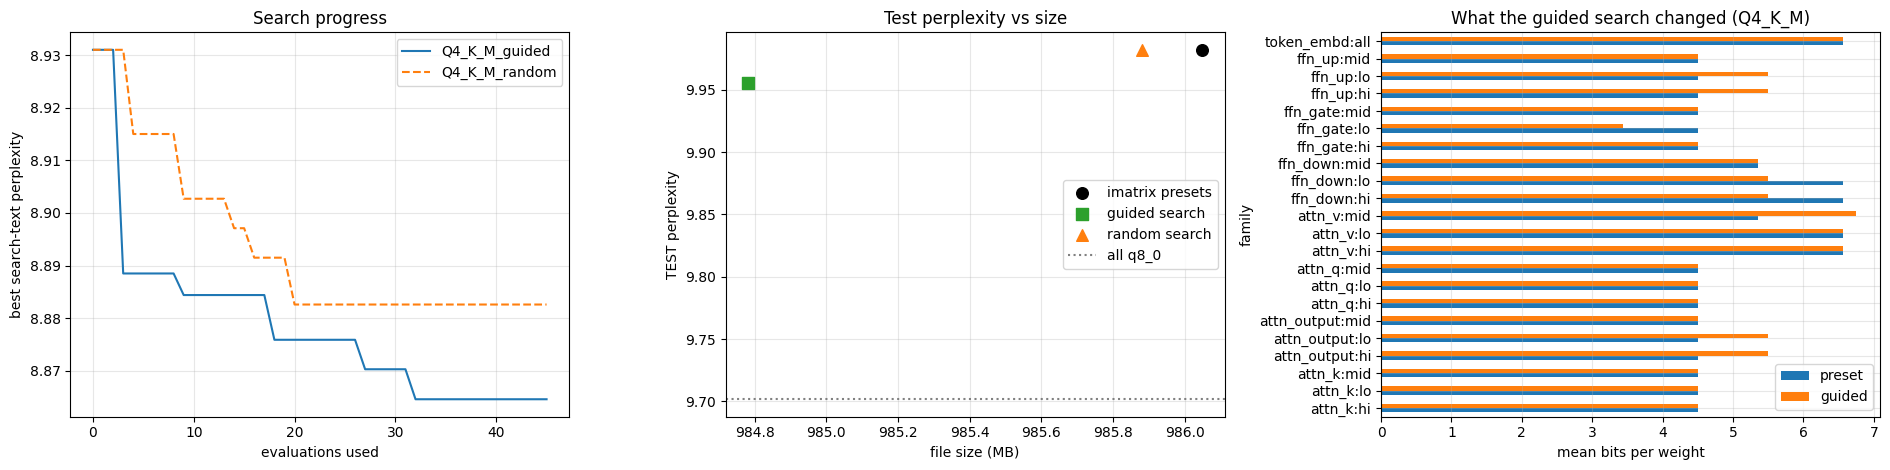

,preset,guided,change
family,,,
attn_output:hi,4.50,5.50,1.00
attn_output:lo,4.50,5.50,1.00
attn_v:mid,5.36,6.75,1.39
ffn_down:hi,6.56,5.50,-1.06
ffn_down:lo,6.56,5.50,-1.06
ffn_gate:lo,4.50,3.44,-1.06
ffn_up:hi,4.50,5.50,1.00
ffn_up:lo,4.50,5.50,1.00


In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))

for run_name, st in [(f"{q}_{m}", (q, m)) for q in SEEDS for m in ("guided", "random")]:
    cur = records[f"{run_name}_seed"]["ppl"]; ys = [cur]
    for k in range(N_EVALS):
        r = records.get(f"{run_name}_e{k:03d}")
        if r is None: break
        if r["accepted"]: cur = r["ppl"]
        ys.append(cur)
    ax[0].plot(range(len(ys)), ys, label=run_name, ls="-" if st[1] == "guided" else "--")
ax[0].set_xlabel("evaluations used"); ax[0].set_ylabel("best search-text perplexity"); ax[0].set_title("Search progress")
ax[0].legend(); ax[0].grid(alpha=.3)

pres = final_df[final_df.config.str.startswith("preset")]
ax[1].scatter(pres.size_mb, pres.test_ppl, c="k", s=70, label="imatrix presets", zorder=3)
for mode, col, mk in [("guided", "tab:green", "s"), ("random", "tab:orange", "^")]:
    d = final_df[final_df.config.str.startswith(mode)]
    ax[1].scatter(d.size_mb, d.test_ppl, c=col, marker=mk, s=70, label=f"{mode} search")
ax[1].axhline(records["ref_q8_test"]["ppl"], color="gray", ls=":", label="all q8_0")
ax[1].set_xlabel("file size (MB)"); ax[1].set_ylabel("TEST perplexity"); ax[1].set_title("Test perplexity vs size")
ax[1].legend(); ax[1].grid(alpha=.3)

q0 = SEEDS[0]
pidx = idx_of(records[f"preset_imx_{q0}"]); gidx = results[f"{q0}_guided"][0]
fam_rows = [{"family": f, "preset": BPW_VEC[pidx[FAM_GROUPS[f]]].mean(), "guided": BPW_VEC[gidx[FAM_GROUPS[f]]].mean()}
            for f in FAMS]
fd = pd.DataFrame(fam_rows).set_index("family")
fd.plot.barh(ax=ax[2]); ax[2].set_xlabel("mean bits per weight"); ax[2].set_title(f"What the guided search changed ({q0})")
ax[2].grid(alpha=.3)
plt.tight_layout()
plt.savefig(RESULTS / f"phase3_{MODEL_NAME}_summary.png", dpi=150)
plt.show()
display(fd.assign(change=fd.guided - fd.preset).round(2).query("abs(change) > 0.01"))

## 12. Save results and the files for the laptop
- `results/phase3_*.jsonl` + CSV: every measurement
- `results/phase3_*_configs.json`: the per-tensor level of each preset and final configuration
- `results/final_models/*.gguf`: preset and final models (about 1 GB each) to benchmark on the laptop with the prebuilt llama.cpp (**download these**; the Output panel lists them)

In [17]:
df = pd.DataFrame(records.values())
df.drop(columns=[c for c in ("levels", "types", "move") if c in df.columns]).to_csv(
    RESULTS / f"phase3_{MODEL_NAME}_all_results.csv", index=False)
final_df.to_csv(RESULTS / f"phase3_{MODEL_NAME}_final_table.csv", index=False)

cfgs = {}
for q in SEEDS:
    cfgs[f"preset_imx_{q}"] = dict(zip([g["id"] for g in GROUPS], records[f"preset_imx_{q}"]["levels"]))
    for mode in ["guided", "random"]:
        cfgs[f"final_{q}_{mode}"] = dict(zip([g["id"] for g in GROUPS], [LEVELS[i] for i in results[f"{q}_{mode}"][0]]))
(RESULTS / f"phase3_{MODEL_NAME}_configs.json").write_text(json.dumps(cfgs, indent=1))

if SAVE_FINAL_GGUFS:
    outdir = RESULTS / "final_models"; outdir.mkdir(exist_ok=True)
    for q in SEEDS:
        if not (outdir / f"{MODEL_NAME}-{q}-imx.gguf").exists():
            quantize(outdir / f"{MODEL_NAME}-{q}-imx.gguf", q, [], imatrix=True)
        for mode in ["guided", "random"]:
            p = outdir / f"{MODEL_NAME}-{q}-{mode}.gguf"
            if not p.exists():
                quantize(p, HIGH, overrides_from_idx(results[f"{q}_{mode}"][0]), imatrix=True)
    print({p.name: f"{p.stat().st_size/1e6:.0f} MB" for p in sorted(outdir.glob('*.gguf'))})

meta = {"model": MODEL_ID, "llama_cpp_commit": LLAMA_COMMIT, "levels": LEVELS, "seeds": SEEDS, "n_evals": N_EVALS,
        "search_chunks": SEARCH_CHUNKS, "ppl_chunks": PPL_CHUNKS, "accept_rel": ACCEPT_REL, "explore": EXPLORE,
        "gpu": sh("nvidia-smi -i 0 --query-gpu=name --format=csv,noheader", check=False),
        "date": time.strftime("%Y-%m-%d %H:%M")}
(RESULTS / f"phase3_{MODEL_NAME}_meta.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

if CLEANUP:
    shutil.rmtree(WORK / "hf", ignore_errors=True)
    shutil.rmtree(MODELS, ignore_errors=True)
    print(sh(f"du -sh {WORK}", check=False))

{'Qwen2.5-1.5B-Q4_K_M-guided.gguf': '985 MB', 'Qwen2.5-1.5B-Q4_K_M-imx.gguf': '986 MB', 'Qwen2.5-1.5B-Q4_K_M-random.gguf': '986 MB'}
$ nvidia-smi -i 0 --query-gpu=name --format=csv,noheader
{
  "model": "Qwen/Qwen2.5-1.5B",
  "llama_cpp_commit": "6b9ba4f",
  "levels": [
    "q3_k",
    "q4_k",
    "q5_k",
    "q6_k",
    "q8_0"
  ],
  "seeds": [
    "Q4_K_M"
  ],
  "n_evals": 45,
  "search_chunks": 80,
  "ppl_chunks": 100,
  "accept_rel": 0.0003,
  "explore": 0.2,
  "gpu": "Tesla T4",
  "date": "2026-10-24 12:35"
}
$ du -sh /kaggle/working
3.2G	/kaggle/working


## How to read the result
1. **Experiment A:** if the embedding at q4_k costs several percent, the Phase 2b failure is explained mostly by that one tensor, and the right place for bits is clear.
2. **Experiment B:** joint damage close to the sum of the parts means a simple model could work after all; much larger means interactions dominate and real measurements are needed (as this notebook does).
3. **Search curves:** guided clearly below random means the sensitivity prior helps; equal curves mean it does not.
4. **Final table:** compare `test_ppl` with the preset at equal or smaller size. The gap between `search_ppl` gain and `test_ppl` gain shows overfitting to the search text.
5. **If there is no gain:** that is a valid result about how well tuned the presets are. The remaining contributions are the speed measurements on your laptop (use the files in `results/final_models/`), the family analysis, and the diagnosis of the model-based approach.

**On the laptop:** run `llama-bench` from `C:\llama-cuda` (`-ngl 99`) and `C:\llama-cpu` (`-ngl 0`, try `-t` values like 6, 8 and 14) on the preset and final GGUFs, with `-r 5` for stable numbers, and record the llama.cpp release tag (`b11851`).